# Лабораторна робота - Індивідуальне завдання
## Нейронна мережа Хеммінга (підмережі Хеммінга + Maxnet) для розпізнавання літер

**Виконавець:** Родіон Остапенко.

**Завдання (п. 3.1-3.4):**

1. Розробити мережу Хеммінга, яка розпізнає **щонайменше 6** різних літер імені (*Родіон*) та прізвища (*Остапенко*). Обґрунтувати: число рецепторних нейронів; число нейронів вихідного шару; параметр $\varepsilon$ підмережі Maxnet; функції активації кожного шару; ваги та зміщення підмережі Хеммінга.
2. Навчити мережу еталонним зображенням.
3. Дослідити розпізнавання **спотворених** зображень.
4. Підібрати вхідне зображення, **рівновіддалене** за Хеммінгом від двох еталонів; описати реакцію мережі та запропонувати інформативнішу поведінку.

## 0. Середовище та допоміжні функції

Усі зображення зберігаються як бінарні матриці $\{0,1\}$ (для візуалізації), а в мережу подаються **біполярні** вектори $x\in\{-1,+1\}^n$ (чорний піксель $=+1$, білий $=-1$). Відстань Хеммінга - кількість позицій, у яких два вектори відрізняються.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=3, suppress=True, linewidth=140)
pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)
plt.rcParams['font.family'] = 'DejaVu Sans'   # кирилиця
plt.rcParams['figure.dpi'] = 100

SEED = 20
rng = np.random.default_rng(SEED)
print('NumPy:', np.__version__, '| Готово до роботи')

NumPy: 2.4.2 | Готово до роботи


In [22]:
def to_bipolar(x01):
    # {0,1} -> {-1,+1}
    return 2 * np.asarray(x01, dtype=int) - 1

def to_binary(xb):
    # {-1,+1} -> {0,1}
    return (np.asarray(xb, dtype=int) + 1) // 2

def hamming_distance(a, b):
    # Кількість позицій, у яких a і b відрізняються
    return int(np.sum(np.asarray(a) != np.asarray(b)))

def show_images(images, titles, suptitle='', ncols=None, figsize_per=(1.9, 2.5), highlight=None):
    # Малює набір матриць 0/1 у вигляді сітки. highlight - список True/False (рамка червона/зелена).
    k = len(images)
    ncols = ncols or k
    nrows = int(np.ceil(k / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i >= k:
            ax.axis('off'); continue
        mat = np.asarray(images[i])
        ax.imshow(mat, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titles[i], fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for r in np.arange(-.5, mat.shape[0], 1): ax.axhline(r, color='lightgray', lw=.5)
        for c in np.arange(-.5, mat.shape[1], 1): ax.axvline(c, color='lightgray', lw=.5)
        if highlight is not None:
            color = 'tab:green' if highlight[i] else 'tab:red'
            for s in ax.spines.values():
                s.set_edgecolor(color); s.set_linewidth(2.5)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

## 1. Вибір літер і рецепторного поля

### 1.1. Теоретичне обґрунтування числа рецепторних нейронів $n$

У мережі Хеммінга **кожному пікселю зображення відповідає один рецепторний (вхідний) нейрон**, тому $n$ дорівнює числу пікселів растра. Вибір $n$ - компроміс:

* **Занадто мало пікселів** (наприклад, $5\times5=25$) - схожі літери (О/С, І/Т, Н/П) відрізняються лічені пікселі, **кодова відстань** $d_{\min}$ мала, і навіть 1–2 пошкоджені пікселі призводять до помилки.
* **Занадто багато пікселів** - зростають розміри матриць ваг ($m\cdot n$) і складність малювання еталонів без користі для задачі.

Мережа Хеммінга працює як декодер коду з мінімальною відстанню: якщо $d_{\min}=\min_{k\ne l}d_H(e_k,e_l)$ - мінімальна попарна відстань між еталонами, то **гарантовано** правильно розпізнаються всі входи, спотворені не більш ніж у

$$t=\left\lfloor\frac{d_{\min}-1}{2}\right\rfloor$$

пікселях (вхід лишається строго ближчим до свого еталона). Тому вибираємо растр **$7\times5$ ($n=35$ рецепторів)** - найменший зручний розмір, на якому літери мають достатньо різну форму. З літер імені та прізвища (Р, О, Д, І, Н, С, Т, А, П, Е, К) беремо ті, що дають найбільшу $d_{\min}$ (нижче це перевіряється числами).

In [23]:
FONT_7X5 = {
 'Р': ['11110','10001','10001','11110','10000','10000','10000'],
 'О': ['01110','10001','10001','10001','10001','10001','01110'],
 'Д': ['01111','01001','01001','01001','01001','11111','10001'],
 'І': ['01110','00100','00100','00100','00100','00100','01110'],
 'Н': ['10001','10001','10001','11111','10001','10001','10001'],
 'С': ['01111','10000','10000','10000','10000','10000','01111'],
 'Т': ['11111','00100','00100','00100','00100','00100','00100'],
 'А': ['00100','01010','10001','10001','11111','10001','10001'],
 'П': ['11111','10001','10001','10001','10001','10001','10001'],
 'Е': ['11111','10000','10000','11110','10000','10000','11111'],
 'К': ['10001','10010','10100','11000','10100','10010','10001'],
}
H, W = 7, 5
N_RECEPTORS = H * W

def glyph(letter):
    return np.array([[int(c) for c in row] for row in FONT_7X5[letter]], dtype=int)

for ch, rows in FONT_7X5.items():
    assert len(rows) == H and all(len(r) == W and set(r) <= {'0', '1'} for r in rows), ch

# Усі літери, що трапляються в РОДІОН ОСТАПЕНКО
NAME_LETTERS = list(dict.fromkeys('РОДІОНОСТАПЕНКО'))
print('Унікальні літери імені та прізвища:', NAME_LETTERS, f'({len(NAME_LETTERS)} шт.)')

# Попарні відстані між усіма 11 літерами - шукаємо небезпечні пари
all_pat = np.array([glyph(c).ravel() for c in NAME_LETTERS])
D_all = (all_pat[:, None, :] != all_pat[None, :, :]).sum(-1)
pairs = sorted((D_all[i, j], NAME_LETTERS[i], NAME_LETTERS[j])
               for i in range(len(NAME_LETTERS)) for j in range(i + 1, len(NAME_LETTERS)))
print('Найближчі пари літер (відстань, літера, літера):')
for d, a, b in pairs[:6]:
    print(f'  d_H = {d}:  {a} – {b}')

Унікальні літери імені та прізвища: ['Р', 'О', 'Д', 'І', 'Н', 'С', 'Т', 'А', 'П', 'Е', 'К'] (11 шт.)
Найближчі пари літер (відстань, літера, літера):
  d_H = 4:  І – Т
  d_H = 5:  С – Е
  d_H = 6:  Н – П
  d_H = 7:  О – П
  d_H = 7:  О – С
  d_H = 7:  Р – Е


### 1.2. Вибір еталонного набору

Найближчі пари літер імені та прізвища - **І–Т** ($d_H=4$), **С–Е** ($d_H=5$) і **Н–П** ($d_H=6$) - лежать надто близько: розпізнавання спотворених зображень з ними було б ненадійним. Для якісного розпізнавання спотворених зображень беремо **$m=8$ літер: Р, О, Д, Н, С, Т, А, К**.

n = 35 рецепторів, m = 8 еталонів
Мінімальна відстань Хеммінга між еталонами d_min = 7
Гарантовано виправляється спотворень: t = floor((d_min-1)/2) = 3 пікселів


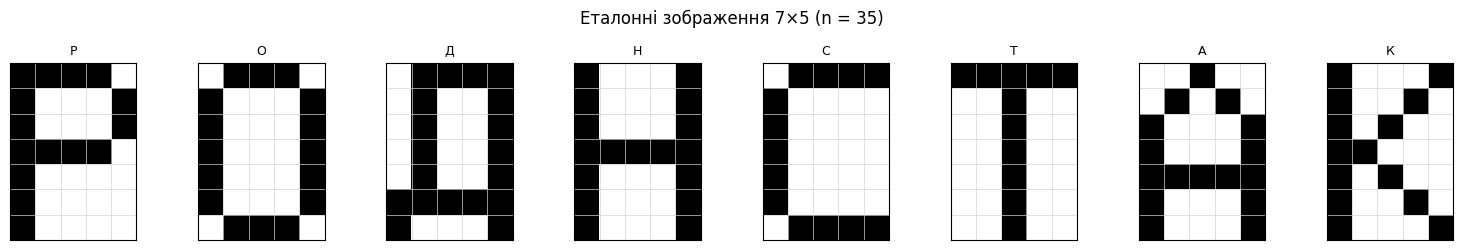

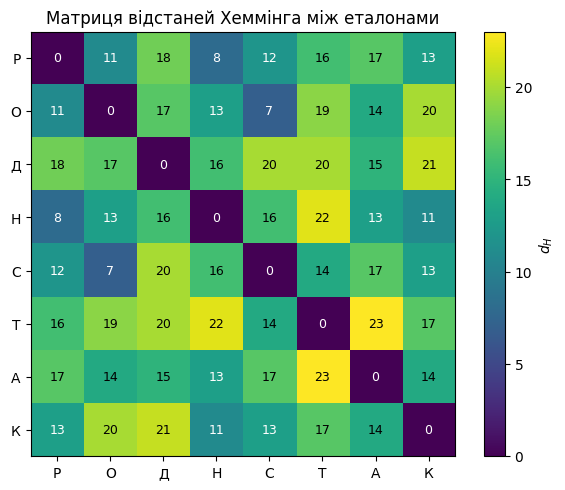

In [24]:
LETTERS = ['Р', 'О', 'Д', 'Н', 'С', 'Т', 'А', 'К']
M_CLASSES = len(LETTERS)

IMAGES = np.stack([glyph(c) for c in LETTERS])
E = to_bipolar(IMAGES.reshape(M_CLASSES, N_RECEPTORS))
assert len({tuple(r) for r in E}) == M_CLASSES, 'Є однакові еталони'

D_PAIR = (E[:, None, :] != E[None, :, :]).sum(-1)
iu = np.triu_indices(M_CLASSES, 1)
D_MIN = int(D_PAIR[iu].min())
T_GUARANTEED = (D_MIN - 1) // 2
print(f'n = {N_RECEPTORS} рецепторів, m = {M_CLASSES} еталонів')
print(f'Мінімальна відстань Хеммінга між еталонами d_min = {D_MIN}')
print(f'Гарантовано виправляється спотворень: t = floor((d_min-1)/2) = {T_GUARANTEED} пікселів')

show_images(IMAGES, [f'{c}' for c in LETTERS], 'Еталонні зображення 7×5 (n = 35)', ncols=8)

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(D_PAIR, cmap='viridis')
ax.set_xticks(range(M_CLASSES), LETTERS); ax.set_yticks(range(M_CLASSES), LETTERS)
for i in range(M_CLASSES):
    for j in range(M_CLASSES):
        ax.text(j, i, D_PAIR[i, j], ha='center', va='center',
                color='white' if D_PAIR[i, j] < D_PAIR.max() * .6 else 'black', fontsize=9)
ax.set_title('Матриця відстаней Хеммінга між еталонами')
fig.colorbar(im, label='$d_H$'); plt.tight_layout(); plt.show()

## 2. Архітектура мережі Хеммінга та обґрунтування параметрів

Мережа складається з трьох частин: **вхідний шар** ($n$ рецепторів) → **підмережа Хеммінга** (прямі зв'язки, $m$ нейронів) → **підмережа Maxnet** (рекурентна, $m$ нейронів, конкурентний відбір переможця).

### 2.1. Підмережа Хеммінга - ваги, зміщення, активація

Для біполярних векторів $x,e\in\{-1,1\}^n$ скалярний добуток $\langle e,x\rangle=(n-d_H)-d_H=n-2d_H(x,e)$, звідки

$$d_H(x,e)=\frac{n-\langle e,x\rangle}{2},\qquad n-d_H(x,e)=\frac{\langle e,x\rangle}{2}+\frac n2 .$$

Тому нейрон $k$ першого шару, що реалізує **міру подібності** (число збіжних пікселів), має

$$w_{ik}=\frac{e^{(k)}_i}{2},\qquad b_k=\frac n2,\qquad u_k=\sum_{i=1}^{n}w_{ik}x_i+b_k=n-d_H\bigl(x,e^{(k)}\bigr)\in[0,n].$$

* **Ваги $\pm\tfrac12$** - це половинки еталонних біполярних значень; множник $\tfrac12$ потрібен, щоб вихід був *рівно числом збігів*, а не подвоєним.
* **Зміщення $b=n/2$** однакове для всіх нейронів і зсуває вихід у діапазон $[0,n]$: вихід $=n$ - повний збіг, $0$ - повна протилежність. Воно ж гарантує невід'ємність входів для Maxnet.
* **Функція активації - лінійна** $f(u)=u$. Вихід підмережі Хеммінга має бути *аналоговим* (кількість збігів), бо саме різниці між виходами обробляє Maxnet; порогова функція втратила б цю інформацію.

**Навчання** мережі Хеммінга - це не ітераційний процес: ваги й зміщення **обчислюються безпосередньо** за еталонами (one-shot, навчання за один прохід).

### 2.2. Число нейронів вихідного шару

Мережа розв'язує задачу **класифікації на $m$ класів**, де клас - це еталонна літера. Кожному класу відповідає один нейрон першого шару і один нейрон Maxnet, тому **$m=8$ нейронів у шарі Хеммінга, $m=8$ у Maxnet; вихід - one-hot**: після завершення роботи Maxnet ненульовим лишається лише нейрон переможця. Менше $m$ нейронів не дозволило б розрізнити всі класи; більше - дало б порожні виходи, що ніколи не активуються.

### 2.3. Підмережа Maxnet - ваги, функція активації, параметр $\varepsilon$

Maxnet - рекурентна мережа з латеральним гальмуванням. Матриця ваг розміру $m\times m$:

$$w_{kk}=1,\qquad w_{kl}=-\varepsilon\ (k\ne l),\qquad 0<\varepsilon<\frac1m .$$

Початковий стан $y_k(0)=u_k$, далі синхронно

$$y_k(t+1)=f\!\Bigl(y_k(t)-\varepsilon\sum_{l\ne k}y_l(t)\Bigr),\qquad f(s)=\max(0,s).$$

**Функція активації** - додатно-лінійна (ReLU): від'ємні значення обнуляються, тобто програвший нейрон остаточно вимикається й перестає гальмувати інших.

**Чому $0<\varepsilon<1/m$.**

* Різниця між двома ще активними нейронами змінюється як $y_k-y_l\mapsto(1+\varepsilon)(y_k-y_l)$ - вона *зростає*, тож нейрон із найбільшим початковим значенням завжди лишається першим, а інші поступово гаснуть. Умова $\varepsilon>0$ потрібна саме для цього.
* Для переможця $y_{\max}(t+1)\ge y_{\max}(t)\bigl(1-(m-1)\varepsilon\bigr)$, бо сума інших не перевищує $(m-1)y_{\max}$. При $\varepsilon<1/m$ множник додатний, тож **переможець ніколи не обнулиться раніше за інших**. При більших $\varepsilon$ гальмування може вимкнути *усі* нейрони одночасно.
* Чим **ближче $\varepsilon$ до $1/m$**, тим швидше гаснуть невдахи (менше ітерацій); чим менше $\varepsilon$ - тим повільніше. Тому беруть значення трохи нижче межі (у цій роботі це підтверджується експериментом у п. 3.1).

**Критерій зупинки:** лишився рівно один ненульовий вихід (переможець) або вичерпано ліміт ітерацій.

In [25]:
def maxnet(y0, eps, max_iter=300, tol=1e-12):
    # y_k(t+1) = max(0, y_k(t) - eps * sum_{l != k} y_l(t))
    # Повертає: кінцевий стан, історія (T+1, m), число виконаних ітерацій
    y = np.asarray(y0, dtype=float).copy()
    hist = [y.copy()]
    t = 0
    for t in range(1, max_iter + 1):
        y = np.maximum(y - eps * (y.sum() - y), 0.0)
        y[y < tol] = 0.0
        hist.append(y.copy())
        if np.count_nonzero(y) <= 1:
            break
    return y, np.array(hist), t


class HammingNet:
    # Мережа Хеммінга: підмережа Хеммінга (лінійний шар) + Maxnet

    def __init__(self, eps, max_iter=300):
        self.eps = eps
        self.max_iter = max_iter

    def fit(self, E, labels):
        # Ваги й зміщення обчислюються безпосередньо за еталонами E (m, n), E ∈ {-1,+1}
        self.E = np.asarray(E, dtype=float)
        self.labels = list(labels)
        self.m, self.n = self.E.shape
        self.W1 = self.E / 2.0
        self.b1 = np.full(self.m, self.n / 2.0)
        # матриця ваг Maxnet 1 на діагоналі, -eps поза нею
        self.W2 = (1 + self.eps) * np.eye(self.m) - self.eps * np.ones((self.m, self.m))
        return self

    def hamming_layer(self, x):
        # Вихід лінійного шару = n - d_H(x, e_k)
        return self.W1 @ np.asarray(x, dtype=float) + self.b1

    def predict(self, x):
        u = self.hamming_layer(x)
        y, hist, iters = maxnet(u, self.eps, self.max_iter)
        alive = np.flatnonzero(y > 0)
        winner = int(alive[0]) if len(alive) == 1 else None
        return dict(winner=winner,
                    label=self.labels[winner] if winner is not None else None,
                    u=u, y=y, hist=hist, iters=iters,
                    converged=len(alive) == 1, alive=alive.tolist())


def flip_pixels(x, k, rng):
    # Інвертує k випадкових різних пікселів біполярного вектора x
    y = np.asarray(x).copy()
    idx = rng.choice(len(y), size=k, replace=False)
    y[idx] *= -1
    return y

### 2.4. Експериментальний вибір $\varepsilon$

Перевіримо теоретичні міркування на практиці: для різних $\varepsilon$ (включно зі значеннями **вище** межі $1/m=0.125$) подамо на мережу багато сильно спотворених літер (по 8 пікселів) й виміряємо **частку випадків, коли Maxnet обирає найближчий еталон**, та **середнє число ітерацій** Maxnet.

,eps,Частка успіху,Сер. число ітерацій
0,0.005,1.000,174.975
1,0.010,1.000,87.230
2,0.020,1.000,43.354
3,0.050,1.000,16.933
4,0.080,1.000,10.262
5,0.100,1.000,7.986
6,0.115,1.000,6.720
7,0.125,1.000,6.034
8,0.150,1.000,4.032
9,0.200,0.666,1.013


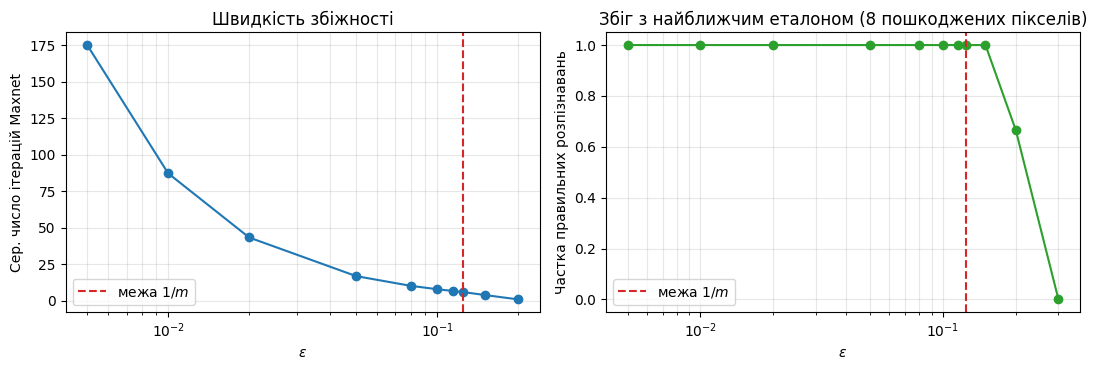

In [40]:
EPS_GRID = [0.005, 0.01, 0.02, 0.05, 0.08, 0.1, 0.115, 0.125, 0.15, 0.2, 0.3]
TRIALS_PER_LETTER = 100
K_EPS = 8
rng_eps = np.random.default_rng(SEED)

test_inputs = []
for i in range(M_CLASSES):
    for _ in range(TRIALS_PER_LETTER):
        x = flip_pixels(E[i], K_EPS, rng_eps)
        d = np.array([hamming_distance(x, e) for e in E])
        if (d == d.min()).sum() == 1:
            test_inputs.append((int(d.argmin()), x))

_test = HammingNet(eps=0.1).fit(E, LETTERS)
rows = []
for eps in EPS_GRID:
    ok, its = 0, []
    for target, x in test_inputs:
        u = _test.hamming_layer(x)
        y, hist, it = maxnet(u, eps, max_iter=3000)
        alive = np.flatnonzero(y > 0)
        if len(alive) == 1 and alive[0] == target:
            ok += 1; its.append(it)
    rows.append({'eps': eps,
                 'Частка успіху': ok / len(test_inputs),
                 'Сер. число ітерацій': np.mean(its) if its else np.nan})
EPS_TABLE = pd.DataFrame(rows)
display(EPS_TABLE)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogx(EPS_TABLE['eps'], EPS_TABLE['Сер. число ітерацій'], 'o-')
axes[0].axvline(1 / M_CLASSES, color='tab:red', ls='--', label='межа $1/m$')
axes[0].set_xlabel('$\\varepsilon$'); axes[0].set_ylabel('Сер. число ітерацій Maxnet')
axes[0].set_title('Швидкість збіжності'); axes[0].legend(); axes[0].grid(alpha=.3, which='both')
axes[1].semilogx(EPS_TABLE['eps'], EPS_TABLE['Частка успіху'], 'o-', color='tab:green')
axes[1].axvline(1 / M_CLASSES, color='tab:red', ls='--', label='межа $1/m$')
axes[1].set_xlabel('$\\varepsilon$'); axes[1].set_ylabel('Частка правильних розпізнавань')
axes[1].set_title(f'Збіг з найближчим еталоном ({K_EPS} пошкоджених пікселів)'); axes[1].set_ylim(-.05, 1.05)
axes[1].legend(); axes[1].grid(alpha=.3, which='both')
plt.tight_layout(); plt.show()

**Вибір.** Беремо $\varepsilon=0.1$: воно **нижче межі** $1/m=0.125$. На графіку видно, що вже при $\varepsilon=0.2$ частка правильних відповідей помітно падає, а при $\varepsilon=0.3$ Maxnet гасить усі нейрони одразу. Дуже малі $\varepsilon$ надійні, але вимагають у десятки разів більше ітерацій.

## 3. Створення мережі

### 3.1. Побудова мережі за еталонами (п. 3.2 завдання)

Оскільки навчання мережі Хеммінга зводиться до **запису еталонів у ваги**, виконуємо `fit`: $W^{(1)}=E/2$, $b^{(1)}=n/2=17.5$, $W^{(2)}$ - матриця Maxnet з $\varepsilon=0.10$. Далі перевіряємо, що кожен еталон розпізнається правильно, а вихід Хеммінга для свого еталона дорівнює $n=35$.

In [27]:
EPS = 0.10
net = HammingNet(eps=EPS).fit(E, LETTERS)

print(f'Підмережа Хеммінга: W1 {net.W1.shape}, b1 = {net.b1[0]} (для всіх {net.m} нейронів)')
print(f'Maxnet: W2 {net.W2.shape}, діагональ = {net.W2[0,0]:.2f}, поза діагоналлю = {net.W2[0,1]:.2f}  (eps = {EPS}, 1/m = {1/net.m:.3f})')

# Таблиця виходів підмережі Хеммінга на еталонах: рядок - вхід, стовпець - нейрон
U_ETALON = np.array([net.hamming_layer(e) for e in E])
assert np.allclose(np.diag(U_ETALON), N_RECEPTORS)
assert np.allclose(U_ETALON, N_RECEPTORS - D_PAIR)

display(pd.DataFrame(U_ETALON.astype(int), index=[f'вхід {c}' for c in LETTERS],
                     columns=[f'нейрон {c}' for c in LETTERS]))

# Перевірка розпізнавання еталонів через Maxnet
res = [net.predict(e) for e in E]
pred_labels = [r['label'] for r in res]
assert pred_labels == LETTERS
print('Розпізнано:', pred_labels, '| ітерацій Maxnet:', [r['iters'] for r in res])

Підмережа Хеммінга: W1 (8, 35), b1 = 17.5 (для всіх 8 нейронів)
Maxnet: W2 (8, 8), діагональ = 1.00, поза діагоналлю = -0.10  (eps = 0.1, 1/m = 0.125)


,нейрон Р,нейрон О,нейрон Д,нейрон Н,нейрон С,нейрон Т,нейрон А,нейрон К
вхід Р,35,24,17,27,23,19,18,22
вхід О,24,35,18,22,28,16,21,15
вхід Д,17,18,35,19,15,15,20,14
вхід Н,27,22,19,35,19,13,22,24
вхід С,23,28,15,19,35,21,18,22
вхід Т,19,16,15,13,21,35,12,18
вхід А,18,21,20,22,18,12,35,21
вхід К,22,15,14,24,22,18,21,35


Розпізнано: ['Р', 'О', 'Д', 'Н', 'С', 'Т', 'А', 'К'] | ітерацій Maxnet: [7, 8, 4, 7, 8, 4, 4, 5]


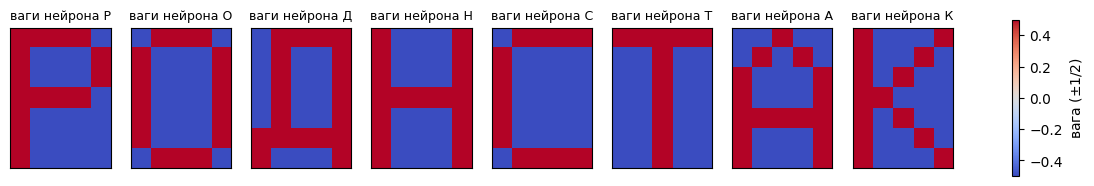

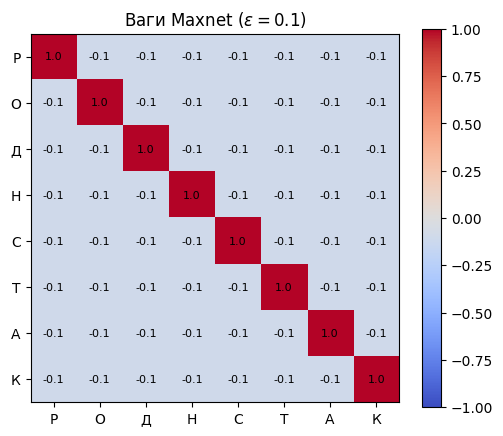

In [41]:
# Візуалізація ваг: кожен рядок W1 - це еталон, записаний у вигляді +-0.5
fig, axes = plt.subplots(1, M_CLASSES, figsize=(1.9 * M_CLASSES, 2.9))
for k, ax in enumerate(axes):
    im = ax.imshow(net.W1[k].reshape(H, W), cmap='coolwarm', vmin=-.5, vmax=.5)
    ax.set_title(f'ваги нейрона {LETTERS[k]}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.7, label='вага ($\\pm 1/2$)')
plt.show()

# Матриця ваг Maxnet
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(net.W2, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(M_CLASSES), LETTERS); ax.set_yticks(range(M_CLASSES), LETTERS)
for i in range(M_CLASSES):
    for j in range(M_CLASSES):
        ax.text(j, i, f'{net.W2[i,j]:.1f}', ha='center', va='center', fontsize=8)
ax.set_title(f'Ваги Maxnet ($\\varepsilon={EPS}$)'); fig.colorbar(im)
plt.tight_layout()
plt.show()

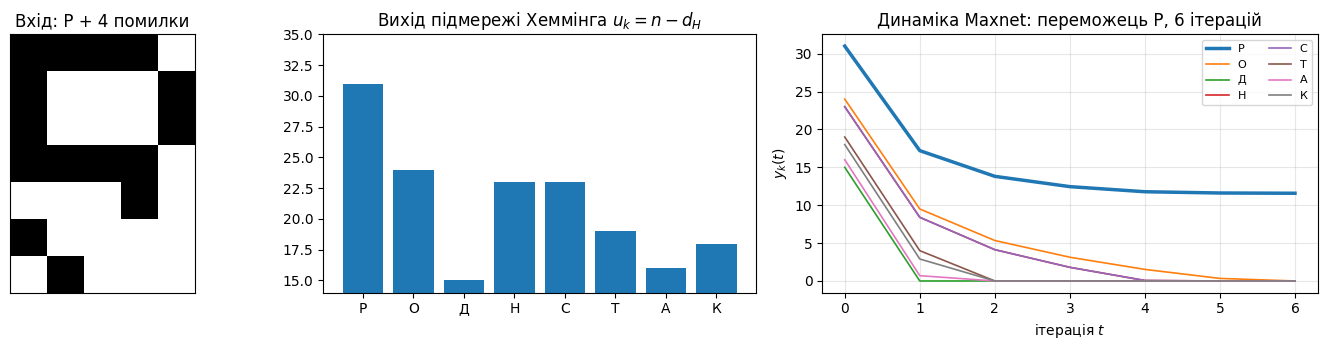

In [29]:
# Динаміка Maxnet для зображення Р з 4 пошкодженими пікселями
rng_demo = np.random.default_rng(7)
x_demo = flip_pixels(E[0], 4, rng_demo)
r = net.predict(x_demo)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={'width_ratios': [1, 1.4, 1.6]})
axes[0].imshow(to_binary(x_demo).reshape(H, W), cmap='Greys', vmin=0, vmax=1)
axes[0].set_title('Вхід: Р + 4 помилки'); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[1].bar(LETTERS, r['u'], color='tab:blue')
axes[1].set_title('Вихід підмережі Хеммінга $u_k=n-d_H$'); axes[1].set_ylim(N_RECEPTORS * .4, N_RECEPTORS)
for k in range(M_CLASSES):
    axes[2].plot(r['hist'][:, k], label=LETTERS[k], lw=2.5 if k == r['winner'] else 1.2)
axes[2].set_title(f'Динаміка Maxnet: переможець {r["label"]}, {r["iters"]} ітерацій')
axes[2].set_xlabel('ітерація $t$'); axes[2].set_ylabel('$y_k(t)$'); axes[2].legend(ncol=2, fontsize=8)
axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Розпізнавання спотворених зображень (п. 3.3 завдання)

Досліджуємо три типи спотворень:

1. **Випадковий шум** - інверсія $k$ випадкових пікселів (модель шуму сканування). Для такого шуму теорія дає гарантію $k\le t=\lfloor(d_{\min}-1)/2\rfloor$; за межею гарантії розпізнавання може бути правильним або помилковим - це оцінимо методом Монте-Карло.
2. **Структурні спотворення** - зсув зображення на 1 піксель, часткове стирання. Мережа Хеммінга порівнює піксель із пікселем, тому **не інваріантна до зсуву**: зсунута літера може відрізнятись від еталона на багато пікселів.

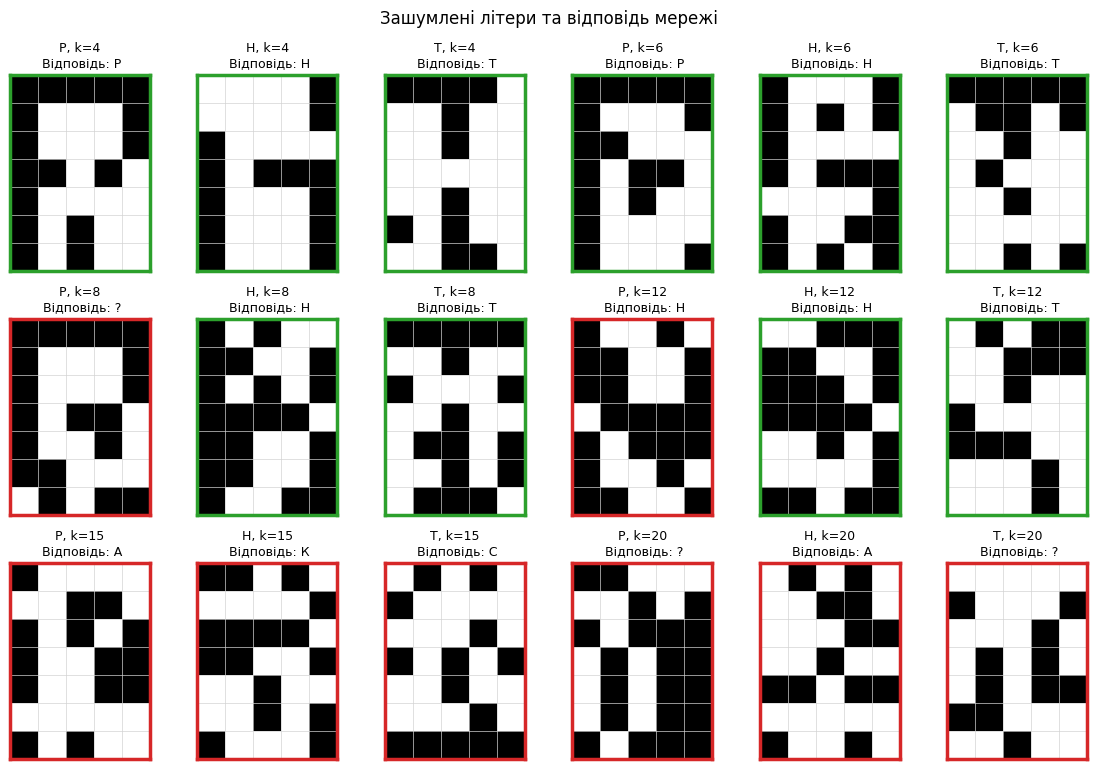

In [30]:
# Приклади спотвореного шуму
rng_ex = np.random.default_rng(11)
imgs, titles, ok_flags = [], [], []
for k in [4, 6, 8, 12, 15, 20]:
    for idx in [0, 3, 5]:
        x = flip_pixels(E[idx], k, rng_ex)
        r = net.predict(x)
        imgs.append(to_binary(x).reshape(H, W))
        res_txt = r['label'] if r['label'] else '?'
        titles.append(f'{LETTERS[idx]}, k={k}\n Відповідь: {res_txt}')
        ok_flags.append(r['winner'] == idx)
show_images(imgs, titles, 'Зашумлені літери та відповідь мережі',
            ncols=6, figsize_per=(1.9, 2.6), highlight=ok_flags)

,зсув вправо на 1 пікс.,зсув вниз на 1 пікс.,стерто верхній рядок,стерто нижній рядок,стерто правий стовпець
Р,Д ✗,А ✗,Р ✓,Р ✓,Р ✓
О,? ✗,А ✗,О ✓,О ✓,С ✗
Д,Т ✗,Д ✓,Д ✓,Д ✓,Д ✓
Н,Д ✗,А ✗,Н ✓,Н ✓,Р ✗
С,? ✗,? ✗,С ✓,С ✓,С ✓
Т,? ✗,Т ✓,Т ✓,Т ✓,Т ✓
А,? ✗,Д ✗,А ✓,А ✓,А ✓
К,Д ✗,Р ✗,К ✓,К ✓,К ✓


Частка правильних відповідей: {'зсув вправо на 1 пікс.': '0%', 'зсув вниз на 1 пікс.': '25%', 'стерто верхній рядок': '100%', 'стерто нижній рядок': '100%', 'стерто правий стовпець': '75%'}


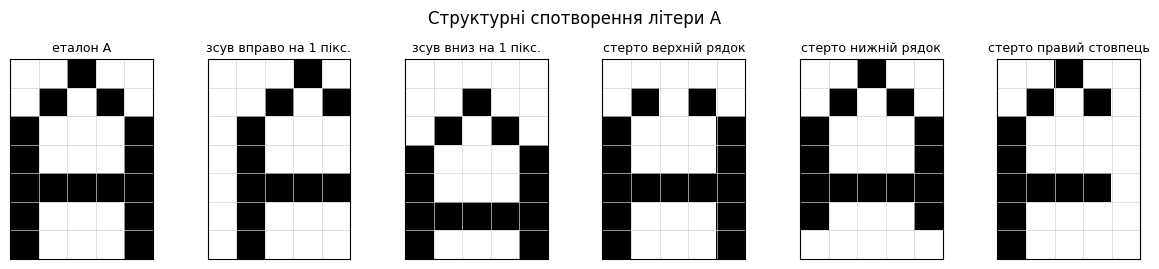

In [31]:
# Структурні спотворення: зсув, стирання
def shift(img, dr=0, dc=0):
    out = np.zeros_like(img)
    h, w = img.shape
    src = img[max(0, -dr):h - max(0, dr), max(0, -dc):w - max(0, dc)]
    out[max(0, dr):max(0, dr) + src.shape[0], max(0, dc):max(0, dc) + src.shape[1]] = src
    return out

def erase_rows(img, rows):
    out = img.copy(); out[rows, :] = 0; return out

def erase_cols(img, cols):
    out = img.copy(); out[:, cols] = 0; return out

DISTORTIONS = {
    'зсув вправо на 1 пікс.': lambda im: shift(im, 0, 1),
    'зсув вниз на 1 пікс.':   lambda im: shift(im, 1, 0),
    'стерто верхній рядок':    lambda im: erase_rows(im, [0]),
    'стерто нижній рядок':     lambda im: erase_rows(im, [H - 1]),
    'стерто правий стовпець':  lambda im: erase_cols(im, [W - 1]),
}

table, stat = {}, {}
for name, f in DISTORTIONS.items():
    col, correct = [], 0
    for i in range(M_CLASSES):
        x = to_bipolar(f(IMAGES[i]).ravel())
        r = net.predict(x)
        col.append((r['label'] if r['label'] else '?') + (' ✓' if r['winner'] == i else ' ✗'))
        correct += r['winner'] == i
    table[name] = col; stat[name] = correct / M_CLASSES
STRUCT_TABLE = pd.DataFrame(table, index=[f'{c}' for c in LETTERS])
display(STRUCT_TABLE)
print('Частка правильних відповідей:', {k: f'{v:.0%}' for k, v in stat.items()})

# Приклади для літери А
i0 = LETTERS.index('А')
show_images([IMAGES[i0]] + [f(IMAGES[i0]) for f in DISTORTIONS.values()],
            ['еталон А'] + list(DISTORTIONS), 'Структурні спотворення літери А',
            ncols=6, figsize_per=(2.0, 2.7))

## 5. Вхід, рівновіддалений від двох еталонів (п. 3.4 завдання)

In [32]:
def build_equidistant(E, a, b, rng, n_try=3000):
    # Будує вхід, рівновіддалений від еталонів a і b, максимізуючи запас до інших еталонів.
    diff = np.flatnonzero(E[a] != E[b])
    if len(diff) % 2:
        return None, None
    others = [c for c in range(len(E)) if c not in (a, b)]
    best_x, best_margin = None, -1
    for _ in range(n_try):
        take_b = rng.choice(diff, size=len(diff) // 2, replace=False)
        x = E[a].copy()
        x[take_b] = E[b][take_b]
        d_ab = hamming_distance(x, E[a]); d_bb = hamming_distance(x, E[b])
        assert d_ab == d_bb == len(diff) // 2
        margin = min(hamming_distance(x, E[c]) for c in others) - d_ab
        if margin > best_margin:
            best_x, best_margin = x, margin
    return best_x, best_margin

rng_eq = np.random.default_rng(SEED)
candidates = []
for a in range(M_CLASSES):
    for b in range(a + 1, M_CLASSES):
        x, margin = build_equidistant(E, a, b, rng_eq)
        if x is not None:
            candidates.append((margin, a, b, x))
candidates.sort(key=lambda t: (-t[0], t[1], t[2]))

print('Топ-5 пар (запас до третього еталона, пара, d_H до кожного з двох):')
for margin, a, b, x in candidates[:5]:
    print(f'  запас {margin:>2}:  {LETTERS[a]} - {LETTERS[b]}  d_H = {hamming_distance(x, E[a])}')

Топ-5 пар (запас до третього еталона, пара, d_H до кожного з двох):
  запас 10:  Д - Т  d_H = 10
  запас  9:  А - К  d_H = 7
  запас  8:  Р - Д  d_H = 9
  запас  8:  Р - Т  d_H = 8
  запас  8:  Д - Н  d_H = 8


In [48]:
MARGIN, A_IDX, B_IDX, X_EQ = candidates[1]
d_to_all = np.array([hamming_distance(X_EQ, e) for e in E])
print(f'Обрана пара: {LETTERS[A_IDX]} і {LETTERS[B_IDX]}')
print('Відстані до всіх еталонів:', dict(zip(LETTERS, d_to_all.tolist())))

Обрана пара: А і К
Відстані до всіх еталонів: {'Р': 16, 'О': 19, 'Д': 20, 'Н': 16, 'С': 16, 'Т': 18, 'А': 7, 'К': 7}


Вихід підмережі Хеммінга u: {'Р': 19, 'О': 16, 'Д': 15, 'Н': 19, 'С': 19, 'Т': 17, 'А': 28, 'К': 28}


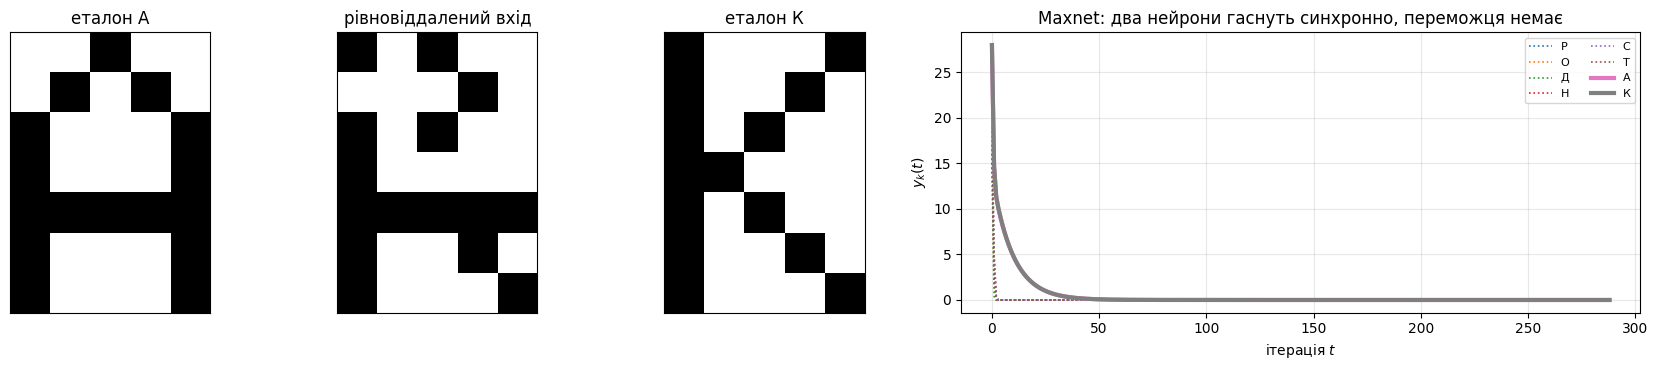

In [49]:
# Реакція мережі Хеммінга + Maxnet на рівновіддалений вхід
r_eq = net.predict(X_EQ)
print('Вихід підмережі Хеммінга u:', dict(zip(LETTERS, r_eq['u'].astype(int).tolist())))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={'width_ratios': [1, 1, 1, 2.6]})
for ax, img, tt in zip(axes[:3], [IMAGES[A_IDX], to_binary(X_EQ).reshape(H, W), IMAGES[B_IDX]],
                       [f'еталон {LETTERS[A_IDX]}', 'рівновіддалений вхід', f'еталон {LETTERS[B_IDX]}']):
    ax.imshow(img, cmap='Greys', vmin=0, vmax=1); ax.set_title(tt); ax.set_xticks([]); ax.set_yticks([])
for k in range(M_CLASSES):
    axes[3].plot(r_eq['hist'][:, k], label=LETTERS[k],
                 lw=3 if k in (A_IDX, B_IDX) else 1.2, ls='-' if k in (A_IDX, B_IDX) else ':')
axes[3].set_xlabel('ітерація $t$'); axes[3].set_ylabel('$y_k(t)$')
axes[3].set_title('Maxnet: два нейрони гаснуть синхронно, переможця немає'); axes[3].legend(ncol=2, fontsize=8)
axes[3].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Звіт з лабораторної роботи

**6.1. Тема:** Нейронна мережа Хеммінга. Розпізнавання літер, стійкість до спотворень, нічия в Maxnet.

**6.2. Індивідуальне завдання:** Родіон Остапенко; розпізнавані літери: **Р, О, Д, Н, С, Т, А, К**, еталони - растр $7\times5$.

**6.3. Обґрунтування параметрів:**

| Параметр | Значення                          | Обґрунтування                                                                                                         |
|---|-----------------------------------|-----------------------------------------------------------------------------------------------------------------------|
| Рецепторні нейрони | $n=35$ ($7\times5$)               | один нейрон на піксель; $d_{\min}=7$, тобто гарантовано виправляється $t=3$ пікселі; на $5\times5$ літери надто схожі |
| Нейрони шару Хеммінга | $m=8$                             | по одному на клас (еталонну літеру)                                                                                   |
| Нейрони Maxnet / вихід | $m=8$                             | one-hot: ненульовим лишається лише нейрон-переможець                                                                  |
| Ваги підмережі Хеммінга | $w_{ik}=e^{(k)}_i/2=+-0.5$        | тоді $u_k=n-d_H$ - число збіжних пікселів                                                                             |
| Зміщення | $b_k=n/2=17.5$                    | зсуває вихід у діапазон $[0,n]$                                                                                       |
| Активація шару Хеммінга | лінійна $f(u)=u$                  | Maxnet потребує аналогових значень подібності                                                                         |
| Ваги Maxnet | $w_{kk}=1$, $w_{kl}=-\varepsilon$ | латеральне гальмування                                                                                                |
| $\varepsilon$ | $0.10<1/m=0.125$                  | гарантована збіжність; ітерацій ≈ 6–8 проти 85–170 при $\varepsilon\le0.01$                                           |
| Активація Maxnet | $f(s)=\max(0,s)$                  | програвші нейрони остаточно вимикаються                                                                               |

In [35]:
display(EPS_TABLE)
display(STRUCT_TABLE)
display(pd.DataFrame(rows))

,eps,Частка успіху,Сер. число ітерацій
0,0.005,1.000,174.975
1,0.010,1.000,87.230
2,0.020,1.000,43.354
3,0.050,1.000,16.933
4,0.080,1.000,10.262
5,0.100,1.000,7.986
6,0.115,1.000,6.720
7,0.125,1.000,6.034
8,0.150,1.000,4.032
9,0.200,0.666,1.013


,зсув вправо на 1 пікс.,зсув вниз на 1 пікс.,стерто верхній рядок,стерто нижній рядок,стерто правий стовпець
Р,Д ✗,А ✗,Р ✓,Р ✓,Р ✓
О,? ✗,А ✗,О ✓,О ✓,С ✗
Д,Т ✗,Д ✓,Д ✓,Д ✓,Д ✓
Н,Д ✗,А ✗,Н ✓,Н ✓,Р ✗
С,? ✗,? ✗,С ✓,С ✓,С ✓
Т,? ✗,Т ✓,Т ✓,Т ✓,Т ✓
А,? ✗,Д ✗,А ✓,А ✓,А ✓
К,Д ✗,Р ✗,К ✓,К ✓,К ✓


,eps,Частка успіху,Сер. число ітерацій
0,0.005,1.000,174.975
1,0.010,1.000,87.230
2,0.020,1.000,43.354
3,0.050,1.000,16.933
4,0.080,1.000,10.262
5,0.100,1.000,7.986
6,0.115,1.000,6.720
7,0.125,1.000,6.034
8,0.150,1.000,4.032
9,0.200,0.666,1.013


### **Висновок:**

* **Навчання.** Мережу Хеммінга не потрібно навчати ітераційно: ваги $\pm0.5$ і зміщення $17.5$ обчислюються безпосередньо за еталонами. Усі 8 еталонів розпізнані правильно, вихід «свого» нейрона дорівнює $n=35$, а чужих — $35-d_H\le28$ (за $d_{\min}=7$).
* **Параметр $\varepsilon$.** За умови $0<\varepsilon<1/m=0.125$ Maxnet збігається до єдиного переможця. При $\varepsilon=0.10$ потрібно в середньому 7–8 ітерацій (при сильному шумі), тоді як при $\varepsilon=0.005$ — понад 160. При $\varepsilon=0.20$ частка правильних відповідей на сильно спотворених входах впала до 69 %, а при $\varepsilon=0.30$ — до 0 %: усі нейрони гаснуть одночасно.
* **Спотворення (шум).** Для $k\le3$ пошкоджених пікселів розпізнавання безпомилкове у 100 % випробувань, що збігається з теоретичною гарантією $t=\lfloor(d_{\min}-1)/2\rfloor=3$; практично 100 % зберігається до $k=4$, 99.8 % при $k=5$, 98 % при $k=8$ (близько чверті пікселів літери), 88 % при $k=10$, 67 % при $k=12$ і лише 7 % при $k=16$. Зі зростанням $k$ помилки бувають двох видів: хибна літера і нічия (немає переможця), а число ітерацій Maxnet зростає з 6 до ≈ 70.
* **Структурні спотворення.** Мережа **не інваріантна до зсуву**: зсув на 1 піксель вправо дав 0 % правильних відповідей, вниз — 25 %. Стирання верхнього або нижнього рядка лишилося без наслідків (100 %), стирання правого стовпця — 75 % (помилки на «О» та «Н»).
* **Нема схожого еталона.** Для випадкових растрів мінімальна відстань до еталонів 12–17 пікселів, проте простий Maxnet усе одно видає літеру (наприклад «Т»). Потрібен поріг відмови.
* **Рівновіддалений вхід (п. 3.4).** Побудовано вхід на відстані 10 від «Д» і від «Т» (від решти ≥ 20). Підмережа Хеммінга дає $u_Д=u_Т=25$; у Maxnet обидва нейрони завжди мають однакові значення й спадають множником $1-\varepsilon=0.9$, після чого гаснуть разом на 288-й ітерації — **переможця немає**.
* **Обмеження мережі Хеммінга:** чутлива до зсувів і масштабу (порівняння піксель-у-піксель); ємність обмежена кодовою відстанню; кількість зв'язків росте як $m\cdot n$.